<a href="https://colab.research.google.com/github/castr1x/ML_an.nykoliuk_3-12/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D1%82%D1%80%D0%B5%D0%BD_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA_26_%D0%9D%D0%B8%D0%BA%D0%BE%D0%BB%D1%8E%D0%BA%D0%B0_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [26]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,108.831816
1,2022-01-02,119.169461
2,2022-01-03,112.594834
3,2022-01-04,107.237722
4,2022-01-05,94.786064


In [27]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [63]:
result = [
    df.tail(10),
    *[min(df['date']),max(df['date'])],
    *[np.mean(df['sales']),np.std(df['sales']),np.std(df['sales']),min(df['sales']),max(df['sales'])]


    ]

for i,j in enumerate(result):
  print('\n',i+1,j,'\n')


 1            date       sales
1451 2025-12-22  161.926749
1452 2025-12-23  160.759657
1453 2025-12-24  148.426949
1454 2025-12-25  123.999900
1455 2025-12-26  152.971189
1456 2025-12-27  162.044431
1457 2025-12-28  165.167940
1458 2025-12-29  163.259228
1459 2025-12-30  157.053559
1460 2025-12-31  141.754690 


 2 2022-01-01 00:00:00 


 3 2025-12-31 00:00:00 


 4 128.36096281309185 


 5 19.58451260916913 


 6 19.58451260916913 


 7 75.40448108864246 


 8 250.5039809399564 



In [69]:
if df['date'].duplicated().sum() > 0:
  print('Дублікати є')
else:
  print('Дублікатів немає')

Дублікатів немає


Дублікати є

## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [70]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,108.831816
2022-01-02,119.169461
2022-01-03,112.594834
2022-01-04,107.237722
2022-01-05,94.786064


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [ ]:
# Ваш код тутні

## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

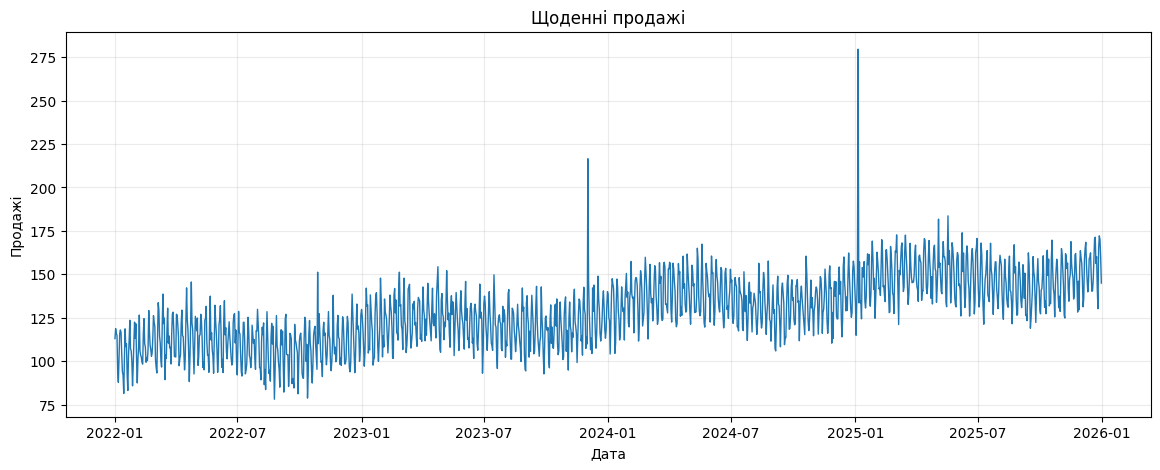

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

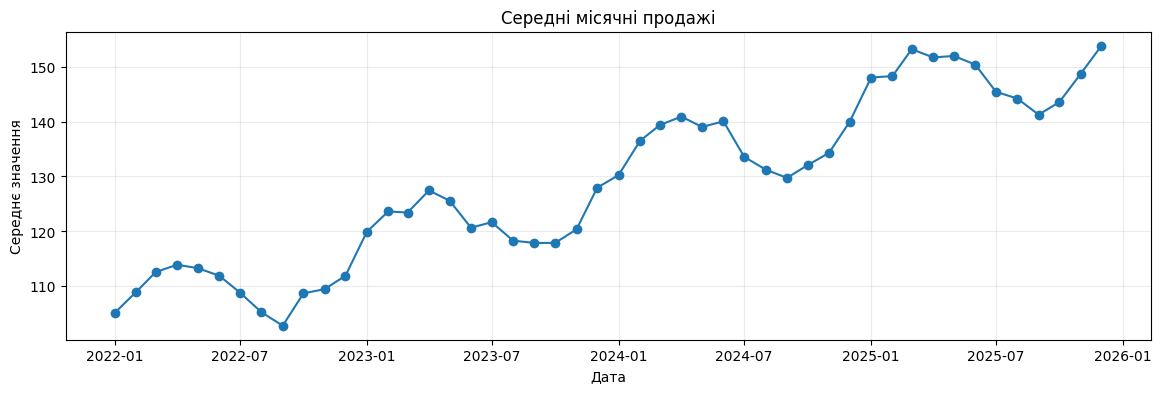

In [ ]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

In [ ]:
# Ваш код тут

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

In [ ]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

In [ ]:
# Ваш код тут

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [ ]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [ ]:
# Ваш код тут

## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [ ]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [ ]:
# Ваш код тут

## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [ ]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [ ]:
# Ваш код тут

## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [ ]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [ ]:
# Ваш код тут

## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [ ]:
# Розкоментуйте, якщо Prophet встановлений.

# from prophet import Prophet
#
# prophet_train = (
#     train.reset_index()
#          .rename(columns={"date": "ds", "sales": "y"})
# )
#
# model_prophet = Prophet(
#     weekly_seasonality=True,
#     yearly_seasonality=True,
#     daily_seasonality=False,
#     seasonality_mode="additive"
# )
#
# model_prophet.fit(prophet_train)
#
# future = model_prophet.make_future_dataframe(
#     periods=len(test),
#     freq="D"
# )
#
# forecast = model_prophet.predict(future)
#
# prophet_pred = (
#     forecast.set_index("ds")
#             .loc[test.index, "yhat"]
# )
#
# evaluate(
#     test["sales"],
#     prophet_pred,
#     train["sales"],
#     seasonality=7
# )

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

In [ ]:
# Ваш код тут

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [ ]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

In [ ]:
ml_train = ml_df.loc[ml_df.index < test.index.min()].copy()
ml_test = ml_df.loc[ml_df.index >= test.index.min()].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [ ]:
# Ваш код тут

## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [ ]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

...

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [ ]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

In [ ]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

In [ ]:
# Ваш код тут

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [ ]:
# Ваш код тут

## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [ ]:
# 1. Первинний аналіз
# Ваш код тут

In [ ]:
# 2. Підготовка даних
# Ваш код тут

In [ ]:
# 3. Візуалізація та STL
# Ваш код тут

In [ ]:
# 4. Train/test split
# Ваш код тут

In [ ]:
# 5. Seasonal naive baseline
# Ваш код тут

In [ ]:
# 6. Статистична модель
# Ваш код тут

In [ ]:
# 7. ML-модель
# Ваш код тут

In [ ]:
# 8. Порівняння метрик
# Ваш код тут

In [ ]:
# 9. Фінальний графік
# Ваш код тут

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

...

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?